# Positions from the 20 % delays: the DCRC1pB-triggered series at -82 V

*Fourth notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

The position distribution of the events on the face, in the plane of the delays between the 20 % rise times of the channels, as in the Run 76 analysis of the UMN group (Matt Fritts, `example_scripts/fritts/run076/r76_analysis_position_new.c` in the `R76Analysis` repository). With `t_X` the 20 % time of channel `X` (his `PXWKr20`):

| quantity | definition | meaning |
|---|---|---|
| `xdel` | `t_E - (t_C + t_D) / 2 - 1 us` | x position: E against the mean of C and D |
| `ydel` | `0.866 (t_D - t_C) + 9 us` | y position: D against C |
| `phidel` | `atan2(ydel, xdel)` | azimuth of the event |
| `afdel` | `t_F - t_A` | centre disc against the outer ring: the radius |

The definitions, the selection and the drawing of the detector are those of `positions-from-delays.ipynb`; the offsets `-1` and `+9` are the empirical ones of his code and are not derived. The times come from `goldsluice`'s `rise_crossing` (`fraction = 0.2`) on the **raw** traces, not on a filtered pulse like his `WKr20`, so they are noisier.

**The data.** The eight Side-2 series near -82 V (HV -82.2 to -81.6 V) that trigger on the phonon channel DCRC1pB (threshold 10), 436 dumps, processed with all seven algorithms by `r76-82v-dcrc1pb.dataset.toml` (on branch `feature/processing`, `data_analysis/R76/processing/`) into `~/goldsluice-output/r76-82v-dcrc1pb`. The notebook reads that output folder directly, so it does not need the definition file. Run with the `darkmatter_cli_env` kernel.

In [1]:
import csv
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors
from matplotlib.patches import Wedge

from goldpan.adapters import parquet

In [2]:
OUT = Path.home() / "goldsluice-output" / "r76-82v-dcrc1pb"     # the output of r76-82v-dcrc1pb.dataset.toml
LETTERS = "ABCDEF"

q = parquet.read(OUT, detector="NAI-S2").quantities          # the quantities only: this output has no traces
series = np.asarray(q["series"]).astype(str)
trigger = np.asarray(q["trigger_type"]).astype(str)
t = {k: np.asarray(q[f"Side2p{k}"]["crossing_time_s"], dtype=float) * 1e6 for k in LETTERS}     # microseconds
integral = np.column_stack([np.asarray(q[f"Side2p{k}"]["integral"], dtype=float) for k in LETTERS])

_here = Path.cwd().resolve()
SERIES_CSV = next(p / "data_analysis" / "R76" / "series_lists" / "nsdf_r76_series.csv"
                  for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "series_lists").is_dir())
with open(SERIES_CSV, newline="") as fh:
    meta = {r["series"]: r for r in csv.DictReader(fh)}

print(f"{len(series):,} events; trigger types: { {str(k): int((trigger == k).sum()) for k in np.unique(trigger)} }")
print(f"{'series':>14} {'HV (V)':>7} {'trigger':>11} {'events':>9}")
for s in np.unique(series):
    print(f"{s:>14} {meta[s]['HV']:>7} {meta[s]['trigger']:>11} {(series == s).sum():>9,}")
print(f"\n{'':28}" + "".join(f"{k:>9}" for k in LETTERS))
print(f"{'median 20 % time (us)':28}" + "".join(f"{np.nanmedian(t[k]):>9.1f}" for k in LETTERS))
print(f"{'events without a time':28}" + "".join(f"{np.isnan(t[k]).mean():>9.1%}" for k in LETTERS))

1,466,349 events; trigger types: {'Physics': 29694, 'Unknown': 1436655}
        series  HV (V)     trigger    events


 07221111_2153   -82.2  DCRC1pB 10   185,413
 07221112_0943   -82.2  DCRC1pB 10   347,850
 07221112_2249   -82.1  DCRC1pB 10   235,967
 07221113_1159     -82  DCRC1pB 10   147,856
 07221114_2141   -81.8  DCRC1pB 10   124,574
 07221115_0845   -81.7  DCRC1pB 10   108,094
 07221115_2109   -81.7  DCRC1pB 10   169,864


 07221116_1003   -81.6  DCRC1pB 10   146,731

                                    A        B        C        D        E        F
median 20 % time (us)           400.5    400.9    406.7    397.3    404.4    399.3
events without a time            0.8%     2.1%     2.3%     0.7%     0.9%     0.8%


## Delays and selection

As in `positions-from-delays.ipynb`: real triggers (`Unknown`; the label `Physics` marks the random triggers, see `integral-on-the-face.ipynb`), the sum of the positive offset-subtracted integrals of the six channels, `total`, above `THRESH`, all six times present, and all six within `WINDOW` of their median, so that every channel times the same pulse. The offset of an integral is its median within the series.

In [3]:
S = integral.copy()
for s in np.unique(series):
    m = series == s
    S[m] -= np.median(integral[m], axis=0)
total = np.clip(S, 0, None).sum(axis=1)

THRESH = 2.0                       # ADC counts x s, as in integral-on-the-face.ipynb
WINDOW = 60.0                      # microseconds: delays of the same pulse are a few microseconds, of different pulses hundreds
OFFSET_X, OFFSET_Y = -1.0, 9.0     # the empirical offsets of Fritts's code

T = np.column_stack([t[k] for k in LETTERS])
xdel = t["E"] - 0.5 * (t["C"] + t["D"]) + OFFSET_X
ydel = 0.866 * (t["D"] - t["C"]) + OFFSET_Y
afdel = t["F"] - t["A"]
phidel = np.degrees(np.arctan2(ydel, xdel))

real = trigger == "Unknown"
pulse = real & (total > THRESH)
finite = np.isfinite(T).all(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)             # an event with no time at all has an all-nan median
    one_pulse = (np.abs(T - np.nanmedian(T, axis=1, keepdims=True)) < WINDOW).all(axis=1)
use = pulse & finite & one_pulse
print(f"real triggers: {real.sum():,}; with total > {THRESH}: {pulse.sum():,}; with six times: {(pulse & finite).sum():,}; "
      f"all six within {WINDOW:.0f} us of their median: {use.sum():,} ({use.sum() / len(use):.1%} of all events)")
for name, v in [("xdel", xdel), ("ydel", ydel), ("afdel", afdel)]:
    p = np.percentile(v[use], [1, 16, 50, 84, 99])
    print(f"{name:>6}  1/16/50/84/99 %: " + "  ".join(f"{x:7.2f}" for x in p) + "  (us)")

real triggers: 1,436,655; with total > 2.0: 465,352; with six times: 464,681; all six within 60 us of their median: 450,703 (30.7% of all events)
  xdel  1/16/50/84/99 %:  -11.64    -6.62     1.15     4.72     9.97  (us)
  ydel  1/16/50/84/99 %:  -10.51    -3.88     1.78     7.01    13.04  (us)
 afdel  1/16/50/84/99 %:   -9.39    -4.11    -1.70     2.06     6.09  (us)


## The position distribution

The event density in the plane of the delays, with the detector underneath. On the face the sectors are `C` upper left, `D` lower left, `E` right; a later pulse in a channel means an event farther from it, so the `x` axis is drawn **reversed** (as the wiki's `x` axis points to the left on this face). The scale is a placeholder: the axes are microseconds, and the radius of the face in microseconds (`R_US`) is not known; it only places the drawing.

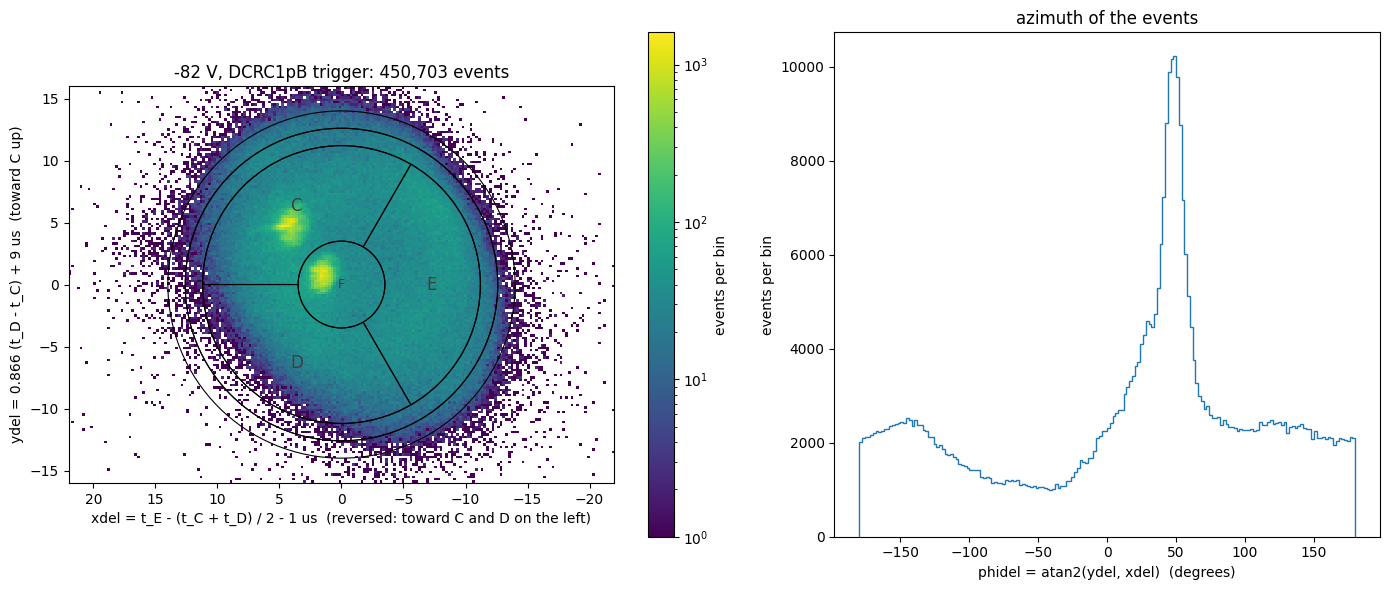

In [4]:
REGIONS = {   # letter -> (inner radius, outer radius, start angle, end angle) in degrees, radius 1 = the face
    "A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360),
    "C": (0.25, 0.80, 60, 180), "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60),
    "F": (0.00, 0.25, 0, 360),
}
R_US = 14.0       # PLACEHOLDER: the radius of the face in microseconds of delay
XR, YR = 22, 16   # the plotted range of xdel and ydel (us)

def draw_detector_mirrored(ax, radius=R_US, label=True, lw=0.8):
    """The face of radius `radius` centred on the origin, mirrored in x, for an axis whose x is reversed."""
    for k, (r_in, r_out, a0, a1) in REGIONS.items():
        ax.add_patch(Wedge((0, 0), r_out * radius, 180 - a1, 180 - a0, width=(r_out - r_in) * radius,
                           facecolor="none", edgecolor="k", linewidth=lw, zorder=3))
        if label and k in "CDE":
            a = np.deg2rad((a0 + a1) / 2)
            ax.text(-0.52 * radius * np.cos(a), 0.52 * radius * np.sin(a), k, ha="center", va="center", fontsize=12, color="0.25", zorder=5)
    if label:
        ax.text(0, 0, "F", ha="center", va="center", fontsize=9, color="0.25", zorder=5)
    ax.set_aspect("equal")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.25, 1]})
h = ax1.hist2d(xdel[use], ydel[use], bins=[200, 160], range=[[-XR, XR], [-YR, YR]], cmap="viridis", norm=colors.LogNorm(), cmin=1, zorder=2)
draw_detector_mirrored(ax1)
ax1.set_xlim(XR, -XR)                      # x reversed
ax1.set_ylim(-YR, YR)
ax1.set_xlabel("xdel = t_E - (t_C + t_D) / 2 - 1 us  (reversed: toward C and D on the left)")
ax1.set_ylabel("ydel = 0.866 (t_D - t_C) + 9 us  (toward C up)")
ax1.set_title(f"-82 V, DCRC1pB trigger: {use.sum():,} events")
fig.colorbar(h[3], ax=ax1, label="events per bin")

ax2.hist(phidel[use], bins=np.linspace(-180, 180, 181), histtype="step", color="C0")
ax2.set_xlabel("phidel = atan2(ydel, xdel)  (degrees)")
ax2.set_ylabel("events per bin")
ax2.set_title("azimuth of the events")
fig.tight_layout()
plt.show()

## The radius: `afdel`

`afdel = t_F - t_A`: an event near the centre reaches the centre disc `F` first (negative), one near the edge reaches the outer ring `A` first (positive). Its distribution, and against the azimuth.

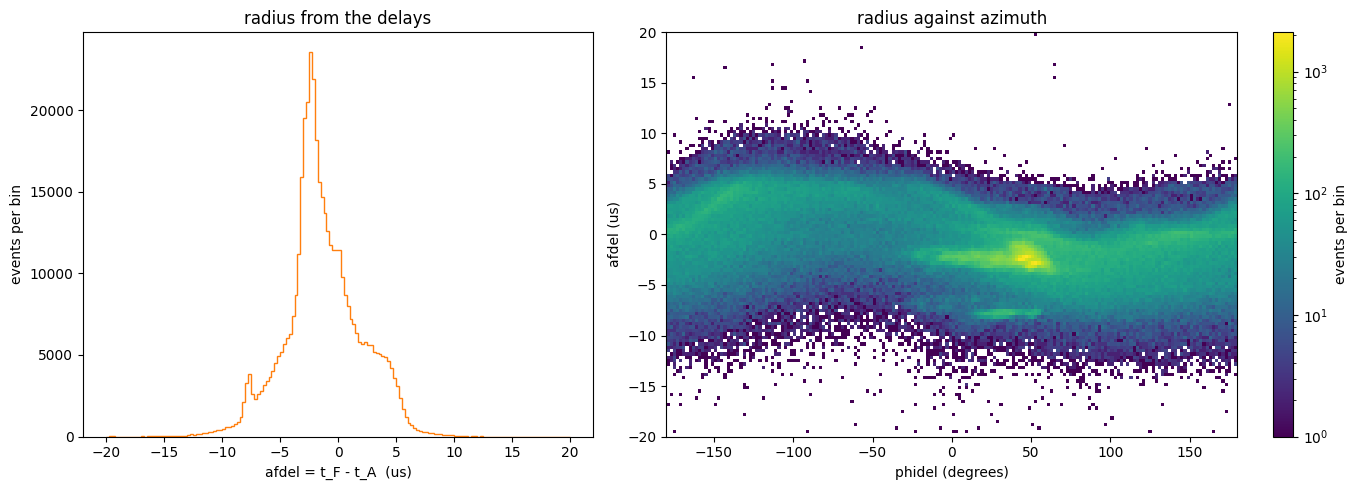

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})
ax1.hist(afdel[use], bins=np.linspace(-20, 20, 161), histtype="step", color="C1")
ax1.set_xlabel("afdel = t_F - t_A  (us)")
ax1.set_ylabel("events per bin")
ax1.set_title("radius from the delays")
h = ax2.hist2d(phidel[use], afdel[use], bins=[180, 120], range=[[-180, 180], [-20, 20]], cmap="viridis", norm=colors.LogNorm(), cmin=1)
ax2.set_xlabel("phidel (degrees)")
ax2.set_ylabel("afdel (us)")
ax2.set_title("radius against azimuth")
fig.colorbar(h[3], ax=ax2, label="events per bin")
fig.tight_layout()
plt.show()

## Series by series

The same plane for each of the eight series, each normalised to its own number of events on one common colour scale, to check that the distribution does not move from series to series (HV drifts from -82.2 to -81.6 V over the five days).

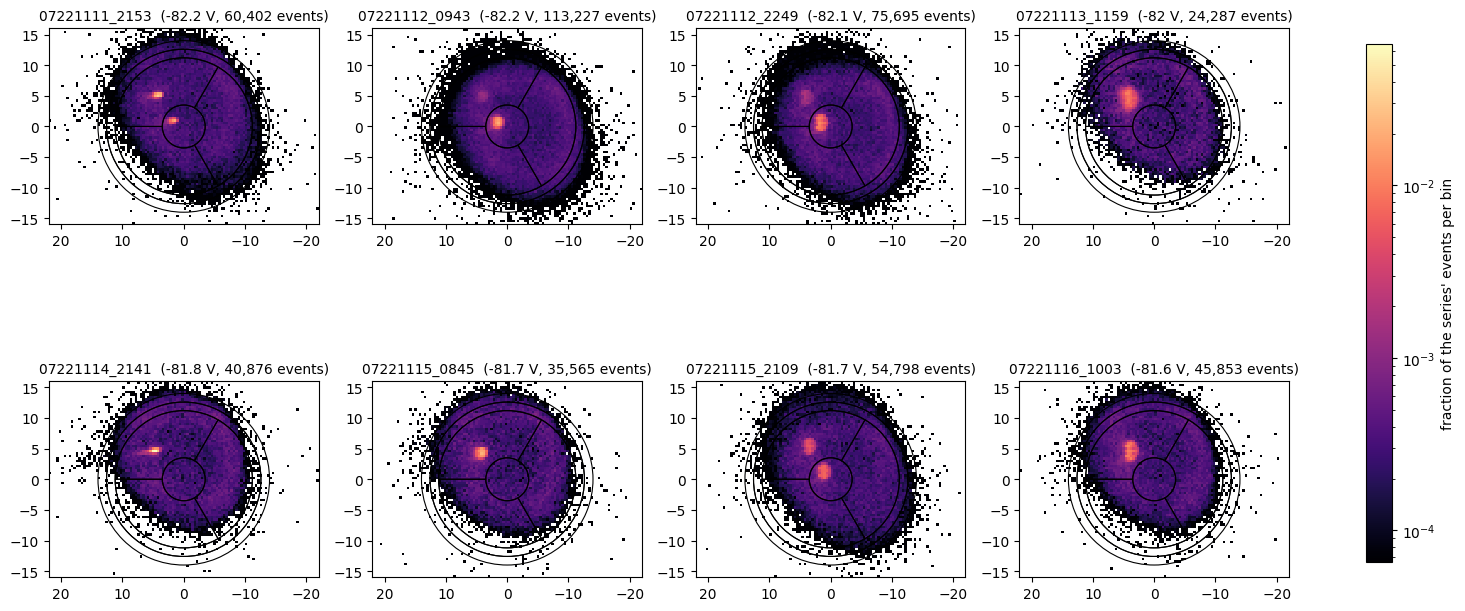

In [6]:
ss = list(np.unique(series))
fig, axes = plt.subplots(2, 4, figsize=(20, 8.4))
dens = []
for s in ss:
    m = use & (series == s)
    d, xe, ye = np.histogram2d(xdel[m], ydel[m], bins=[110, 80], range=[[-XR, XR], [-YR, YR]])
    dens.append(d / max(m.sum(), 1))
vmax = max(d.max() for d in dens)
for ax, s, d in zip(axes.flat, ss, dens):
    c = ax.pcolormesh(xe, ye, np.where(d > 0, d, np.nan).T, cmap="magma", norm=colors.LogNorm(vmin=vmax * 1e-3, vmax=vmax), zorder=2)
    draw_detector_mirrored(ax, label=False)
    ax.set_xlim(XR, -XR)
    ax.set_ylim(-YR, YR)
    ax.set_title(f"{s}  ({meta[s]['HV']} V, {(use & (series == s)).sum():,} events)", fontsize=10)
fig.colorbar(c, ax=axes, shrink=0.8, label="fraction of the series' events per bin")
plt.show()

**What this shows, and what is not done.** The distribution of the DCRC1pB-triggered events at -82 V in the plane of the 20 % delays, its azimuth and radius, and the eight series side by side. Not done: millimetres (`R_US` is a placeholder), the offsets (taken from Fritts's code, not derived), filtered times, and a check of the pulse position (`pretrigger_samples`) in these series, whose readout is assumed to be DCRC_RUN76. The trigger is a phonon channel (DCRC1pB), so the events are not selected the same way as in the NaI-triggered series: compare with those before reading a pattern as a property of the detector.